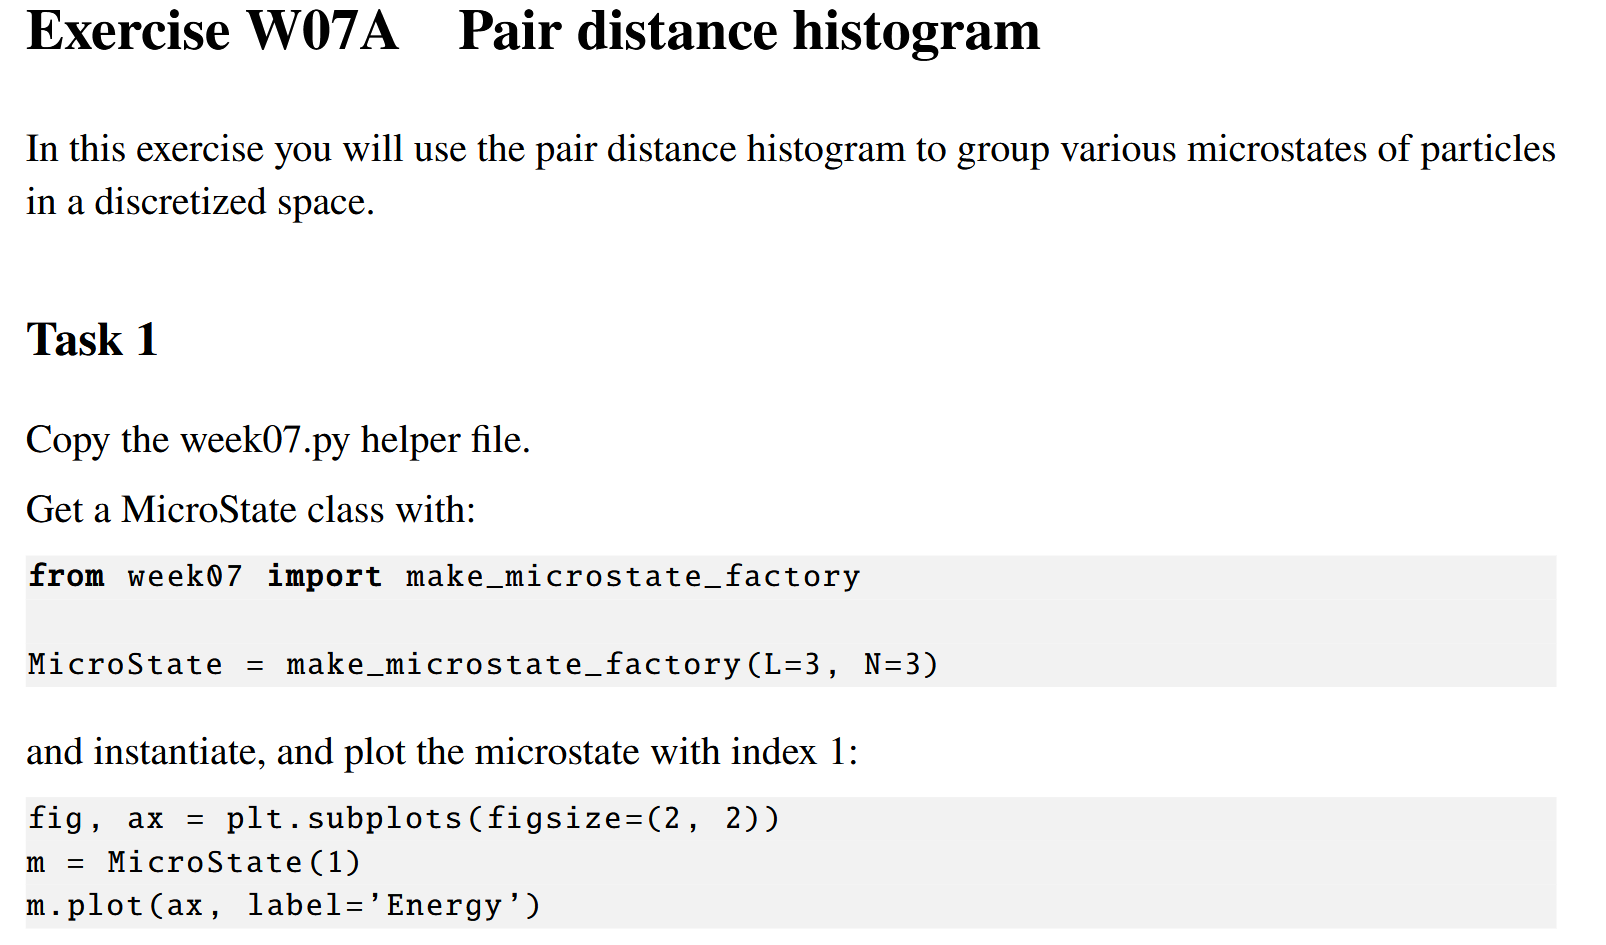

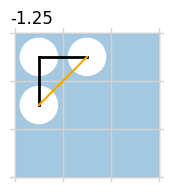

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from week07 import *

MicroState = make_microstate_factory(L=3, N=3)

fig, ax = plt.subplots(figsize=(2,2))
m = MicroState(1)
m.plot(ax, label='Energy')

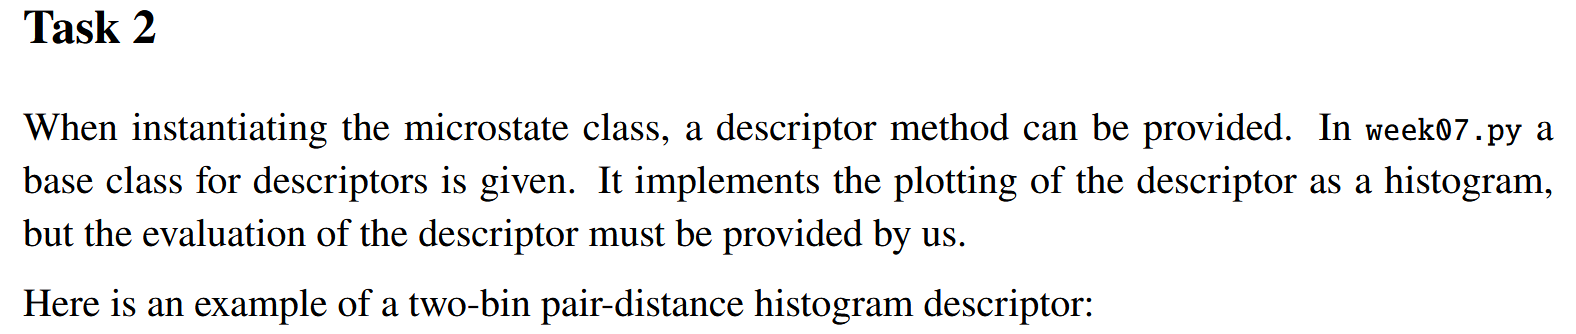

[[0. 2.]
 [1. 2.]
 [0. 1.]]
[2, 1]


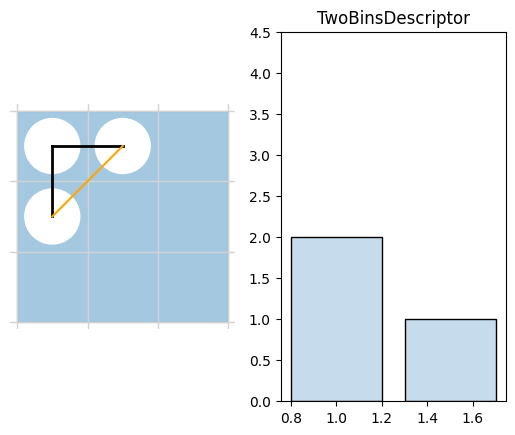

In [2]:
from scipy.spatial.distance import pdist

class TwoBinsDescriptor(DescriptorBase):

    centers = [1.0, 1.5]
    ylim = [0.0, 4.5]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist = np.histogram(dist_vector, self.edges)
        return hist[0].tolist()

descriptor_method_2d = TwoBinsDescriptor()

print(m.pos)

MicroState = make_microstate_factory(N=3, L=3, descriptor_method=descriptor_method_2d)
m = MicroState(1)
print(m.descriptor)

fig, ax = plt.subplots(1, 2)

m.plot(ax[0])
m.plot_descriptor(ax[1])

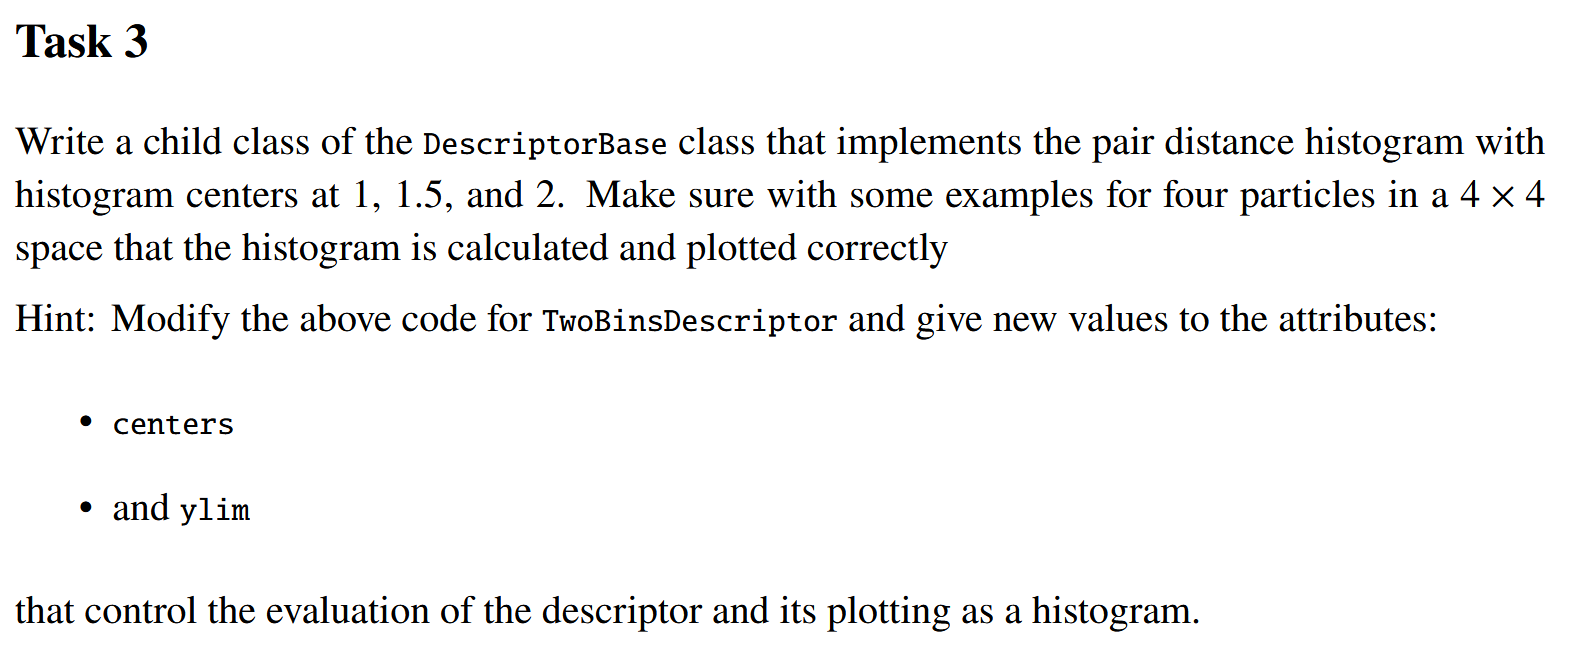

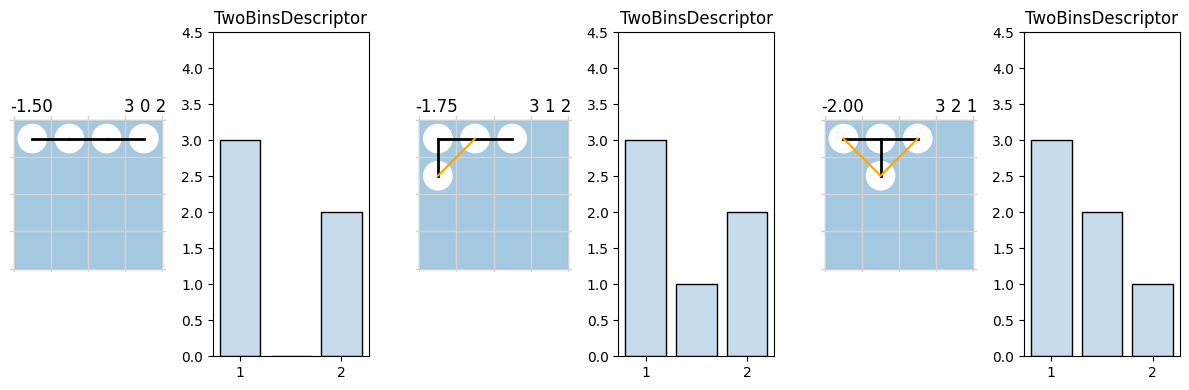

In [ ]:
class ThreeBinsDescriptor(DescriptorBase):

    centers = [1.0, 1.5, 2.0]
    ylim = [0.0, 4.5]

    def __call__(self, pos):
        dist_vector = pdist(pos)
        hist = np.histogram(dist_vector, self.edges)
        return hist[0].tolist()

descriptor_method_2d = ThreeBinsDescriptor()

MicroState = make_microstate_factory(N=4, L=4, descriptor_method=descriptor_method_2d)


fig, ax = plt.subplots(1, 6, figsize=(6*2, 4))

for i in range(3):
    m = MicroState(i)
    m.plot(ax[2*i], label='Dual')
    m.plot_descriptor(ax[2*i+1])

plt.tight_layout()

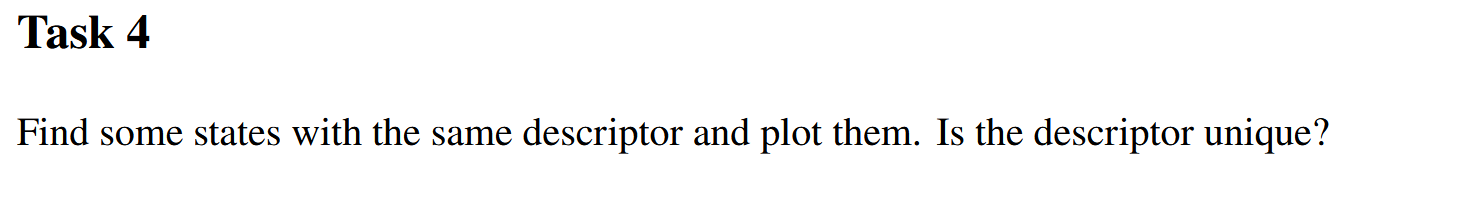

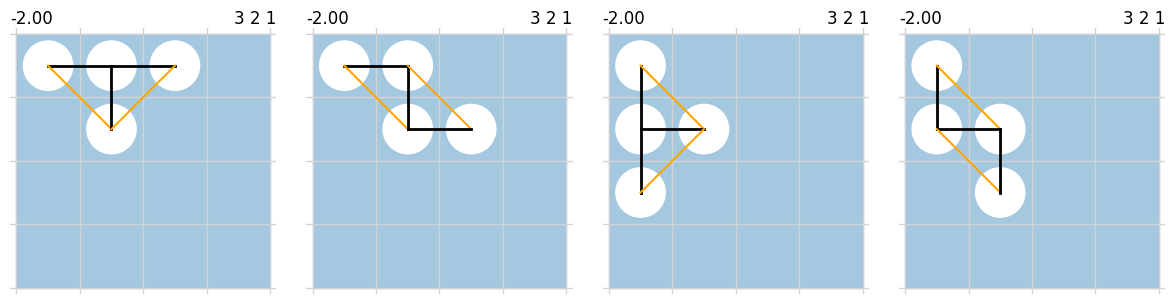

In [5]:
# Find some states with the same descriptor to test uniqueness[cite: 4]
target_descriptor = MicroState(2).descriptor
matching_states = []

# Search for matching states
for i in range(MicroState.total): 
    if MicroState(i).descriptor == target_descriptor:
        matching_states.append(i)

fig, axes = plt.subplots(1, len(matching_states[:4]), figsize=(3 * len(matching_states[:4]), 3))
for ax, idx in zip(axes, matching_states[:4]):
    MicroState(idx).plot(ax, label='Dual')
plt.tight_layout()
plt.show()